# RAG con LangChain y LangGraph: pipeline con reescritura de consultas frente a un agente con el RAG como herramienta

**Autor:** Jheison Martinez Bolivar
**Actividad:** Implementación de agentes con LangChain y LangGraph y su impacto en la interacción con un LLM
**Corpus:** artículos de referencia del proyecto astro-denoise (`astro-denoise/referencias/asreview/pdfs`)
**Modelos locales:** `qwen3.5:4b` (generación) y `nomic-embed-text` (embeddings), servidos por Ollama
**Fecha:** noviembre de 2026

## Contexto: astro-denoise

astro-denoise es la tesis de maestría del autor: una plataforma de benchmarking reproducible que compara métodos de reducción de ruido en imágenes simuladas DC2 del Vera C. Rubin Observatory, evaluando la recuperación de fuentes débiles, la calidad de la imagen y el coste computacional de cada método. Página del proyecto: https://univerlab.org/astro-denoise

El corpus de este notebook son los artículos de referencia que se evaluaron para el documento de la tesis durante la revisión de literatura, cribados con ASReview y descargados en PDF. El asistente que se construye aquí sirve para consultar esa base de conocimiento en español.

## Objetivo

Este notebook construye un asistente que responde preguntas en español sobre la base de conocimiento formada por los artículos científicos del proyecto astro-denoise, que están en inglés. La pregunta que lo guía es qué cambia en la interacción con el LLM cuando se le añaden recuperación, herramientas y memoria.

El sistema es un grafo de LangGraph con cuatro nodos: un nodo **reescribe** la pregunta (la traduce y genera variantes técnicas), otro **recupera** fragmentos por similitud coseno con esas variantes, un tercero **cuenta** artículos con una herramienta cuando la pregunta lo pide, y el último **genera** la respuesta citando archivo y página. Un checkpointer da memoria entre turnos. Después se construye un **agente** de LangChain que recibe esas mismas herramientas, incluido el RAG empaquetado como herramienta, y decide por sí mismo cuándo y cómo usarlas. Las cuatro configuraciones (LLM solo, RAG fijo, pipeline y agente) se comparan con las mismas cinco preguntas.

> Si Ollama no está disponible o falta un modelo, la ejecución se detiene. La comparación final se guarda en un archivo de caché para que reejecutar el notebook no vuelva a invocar el modelo sin que se pida.

## 1. Fundamentación y fuentes

La generación aumentada por recuperación (RAG) condiciona la respuesta con fragmentos recuperados de una base externa, de modo que pueda trazarse a una fuente. La reescritura de consultas adapta la pregunta del usuario antes de recuperar, porque la formulación original rara vez es la mejor para el buscador. Las herramientas delegan en código determinista lo que un LLM calcula mal, como contar. LangGraph expresa el flujo como un grafo de estados y el checkpointer persiste ese estado por hilo, que es lo que da memoria.

1. Lewis et al. (2020), *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks*: https://arxiv.org/abs/2005.11401
2. Ma et al. (2023), *Query Rewriting for Retrieval-Augmented Large Language Models*: https://arxiv.org/abs/2305.14283
3. Schick et al. (2023), *Toolformer: Language Models Can Teach Themselves to Use Tools*: https://arxiv.org/abs/2302.04761
4. Nussbaum et al. (2024), *Nomic Embed: Training a Reproducible Long Context Text Embedder*: https://arxiv.org/abs/2402.01613
5. Documentación de LangGraph: https://langchain-ai.github.io/langgraph/
6. Documentación de LangChain: https://docs.langchain.com/oss/python/langchain/overview
7. Yao et al. (2022), *ReAct: Synergizing Reasoning and Acting in Language Models*: https://arxiv.org/abs/2210.03629

### Componentes de LangChain usados y cómo se conectan con el LLM

| Componente | Para qué se usa | Conexión con el LLM |
|---|---|---|
| `ChatOllama` | Cliente del modelo local `qwen3.5:4b` | Toda llamada al LLM pasa por él, con temperatura 0 y semilla fija |
| `RecursiveCharacterTextSplitter` | Corta las páginas en chunks | Define la unidad de texto que luego llega al prompt |
| `OllamaEmbeddings` + `Chroma` | Vectoriza chunks y consultas, busca por similitud coseno | Selecciona el contexto que se inserta en el prompt |
| `ChatPromptTemplate` + `\|` + `StrOutputParser` | Cadena RAG en LCEL | Arma el prompt con contexto y pregunta, y extrae el texto de la respuesta |
| `with_structured_output` | Plan de consulta tipado con Pydantic | Obliga al LLM a devolver un objeto validado en lugar de texto libre |
| `@tool` | `buscar_literatura` (el RAG como herramienta) y `contar_articulos` | El nombre, la firma y el docstring son lo que el LLM lee para decidir cuándo usarlas |
| `StateGraph` (LangGraph) | Pipeline orquestado | El código fija el orden de los pasos; el LLM solo trabaja dentro de cada nodo |
| `create_agent` | Agente ReAct | El LLM decide qué herramienta llamar, con qué argumentos y cuándo parar |
| `MemorySaver` | Memoria por `thread_id` | Guarda el historial y lo reinyecta al LLM en el turno siguiente |

In [1]:
import json
import re
import sys
import time
from pathlib import Path
from typing import Literal

import matplotlib.pyplot as plt
import ollama
import pandas as pd
from langchain.agents import create_agent
from langchain.tools import tool
from langchain_core.messages import AIMessage, HumanMessage, SystemMessage, ToolMessage
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_ollama import ChatOllama
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import END, START, MessagesState, StateGraph
from pydantic import BaseModel

sys.path.insert(0, str(Path.cwd()))
import rag_pipeline as rp

MODEL = "qwen3.5:4b"
installed = {item.model for item in ollama.Client().list().models}
for required in (MODEL, f"{rp.EMBED_MODEL}:latest"):
    if required not in installed:
        raise RuntimeError(f"Falta el modelo {required!r}. Ejecuta `ollama pull {required.split(':')[0]}`.")

llm = ChatOllama(model=MODEL, temperature=0, seed=42, reasoning=False, num_ctx=8192)
vectorstore = rp.get_vectorstore()
print("LLM:", MODEL, "| embeddings:", rp.EMBED_MODEL, "| chunks en el índice:", vectorstore._collection.count())

LLM: qwen3.5:4b | embeddings: nomic-embed-text | chunks en el índice: 23666


## 2. Corpus e indexación

Los PDFs se leyeron con `pypdf`, se cortaron con un `RecursiveCharacterTextSplitter` y los chunks se indexaron en Chroma con embeddings de `nomic-embed-text`. La indexación tarda varios minutos, así que vive en `rag_pipeline.py` y deja un manifiesto con los archivos procesados y la causa de cada fallo; el notebook solo lo lee. La tabla de fallos separa los archivos que sí son PDFs de los que no, comprobando la firma `%PDF`.

El splitter corta primero por párrafos, si el trozo sigue siendo grande por líneas, luego por frases y por último por palabras, hasta que cada chunk cabe en 1000 caracteres. El solapamiento de 150 caracteres repite el final de un chunk al inicio del siguiente para que una idea cortada en la frontera no se pierda. La segunda celda lo comprueba en una página real: cuántos chunks produce y si el final de uno reaparece al inicio del siguiente.

,PDFs en la carpeta,indexados,fallidos,chunks totales
0,295,255,40,23666


,,archivos
tipo_de_archivo,error,
no es PDF (HTML u otro),PdfStreamError,36
PDF real,LimitReachedError,4


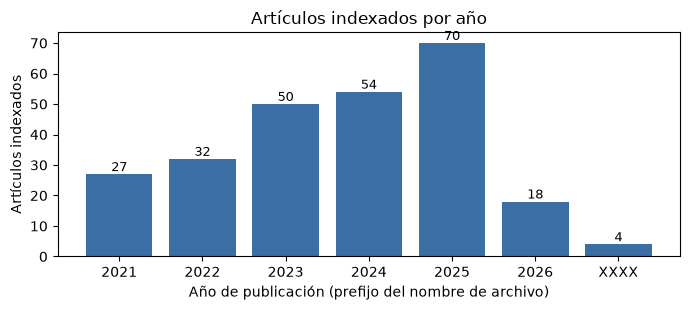

In [2]:
manifest = rp.load_manifest()
indexed = pd.Series(manifest["indexed"], name="chunks")
failed = pd.Series(manifest["failed"], name="error")


def file_kind(name):
    with open(rp.PDF_DIR / name, "rb") as handle:
        return "PDF real" if handle.read(4) == b"%PDF" else "no es PDF (HTML u otro)"


display(
    pd.DataFrame(
        {
            "PDFs en la carpeta": [len(list(rp.PDF_DIR.glob("*.pdf")))],
            "indexados": [len(indexed)],
            "fallidos": [len(failed)],
            "chunks totales": [int(indexed.sum())],
        }
    )
)
display(pd.DataFrame({"tipo_de_archivo": failed.index.map(file_kind), "error": failed.str.split(":").str[0].values}).value_counts().rename("archivos").to_frame())

by_year = indexed.groupby(indexed.index.str[:4]).size()
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(by_year.index, by_year.values, color="#3b6ea5")
ax.set_xlabel("Año de publicación (prefijo del nombre de archivo)")
ax.set_ylabel("Artículos indexados")
ax.set_title("Artículos indexados por año")
for x, y in zip(by_year.index, by_year.values):
    ax.text(x, y + 1, str(y), ha="center", fontsize=9)
plt.tight_layout()
plt.show()

In [3]:
sample_pdf = next(rp.PDF_DIR.glob("2025_R_bgrem*.pdf"))
page = rp.read_pages(sample_pdf)[2]
pieces = rp.splitter.split_text(page.page_content)
print("Archivo:", sample_pdf.name, "| página:", page.metadata["page"])
print("Caracteres de la página:", len(page.page_content), "| chunks:", len(pieces), "| tamaños:", [len(piece) for piece in pieces])
print("\nFinal del chunk 1:\n   ...", pieces[0][-rp.CHUNK_OVERLAP:].replace("\n", " "))
print("\nInicio del chunk 2:\n   ", pieces[1][: rp.CHUNK_OVERLAP + 30].replace("\n", " "), "...")

Archivo: 2025_R_bgrem_background_noise_remover_astronomical_images.pdf | página: 3
Caracteres de la página: 5962 | chunks: 7 | tamaños: [993, 969, 947, 974, 974, 976, 892]

Final del chunk 1:
   ... tion from the IEM is significant, could result in spurious source detection and also hide a faint source population. To test the possibility of remov-

Inicio del chunk 2:
    is significant, could result in spurious source detection and also hide a faint source population. To test the possibility of remov- ing this IEM with BGRem, we have used the lates ...


## 3. Recuperación por similitud coseno

La colección de Chroma se creó con métrica coseno (`hnsw:space = cosine`). Chroma devuelve la **distancia coseno**, que es 1 menos la similitud, y el notebook trabaja con la **similitud**: 1 significa misma dirección en el espacio de embeddings y valores bajos significan fragmentos sin relación. No es una probabilidad de acierto; sirve para comparar resultados y para decidir qué tan cerca debe estar un fragmento para considerarlo evidencia.

Se mide la similitud del mejor fragmento para tres grupos de consultas: dentro del tema en inglés, las mismas en español y fuera del tema. Se parte de la hipótesis de que `nomic-embed-text`, entrenado sobre todo en inglés, separa bien el inglés técnico del texto fuera de tema pero no el español. Del hueco entre el mejor grupo fuera de tema y el peor grupo en inglés se toma el umbral mínimo de similitud para aceptar un fragmento. También se mide cuántos de los cinco primeros archivos recuperados coinciden entre la consulta en español y su traducción.

In [4]:
EN_QUERIES = [
    "diffusion models for astronomical image denoising",
    "metrics PSNR SSIM for denoising evaluation",
    "self-supervised denoising without clean images",
    "background noise removal in sky images",
]
ES_QUERIES = [
    "modelos de difusión para eliminar ruido en imágenes astronómicas",
    "métricas PSNR SSIM para evaluar el denoising",
    "eliminar ruido sin imágenes limpias de referencia",
    "eliminación de ruido de fondo en imágenes del cielo",
]
OFF_QUERIES = [
    "producto interno bruto de Colombia en 2025",
    "weather forecast tomorrow in Paris",
    "receta de arepas con queso",
    "stock market prices of technology companies",
]


def top_hits(query, k=1):
    return [(doc, 1 - distance) for doc, distance in vectorstore.similarity_search_with_score(query, k=k)]


rows = []
for group, queries in {"tema, inglés": EN_QUERIES, "tema, español": ES_QUERIES, "fuera de tema": OFF_QUERIES}.items():
    for query in queries:
        rows.append({"grupo": group, "consulta": query[:52], "similitud del mejor fragmento": round(top_hits(query)[0][1], 3)})
calibration = pd.DataFrame(rows)
display(calibration.groupby("grupo")["similitud del mejor fragmento"].agg(["min", "max"]).loc[["tema, inglés", "tema, español", "fuera de tema"]])

SIM_MIN = round((calibration.query("grupo == 'fuera de tema'")["similitud del mejor fragmento"].max() + calibration.query("grupo == 'tema, inglés'")["similitud del mejor fragmento"].min()) / 2, 2)
common = [
    len({d.metadata["source"] for d, _ in top_hits(es, 5)} & {d.metadata["source"] for d, _ in top_hits(en, 5)})
    for es, en in zip(ES_QUERIES, EN_QUERIES)
]
print("Umbral de similitud (punto medio del hueco):", SIM_MIN)
print("Archivos comunes entre consulta en español y en inglés (de 5):", common)

,min,max
grupo,,
"tema, inglés",0.747,0.862
"tema, español",0.529,0.679
fuera de tema,0.457,0.584


Umbral de similitud (punto medio del hueco): 0.67
Archivos comunes entre consulta en español y en inglés (de 5): [0, 3, 0, 0]


## 4. Preguntas de evaluación y configuraciones de referencia

Se fijan cinco preguntas que cubren lo que cada capa debería resolver o fallar: dos de búsqueda de contenido, una de conteo, una que combina filtro por año con búsqueda y una sin respuesta en el corpus. El contrato de salida es el mismo en todas las configuraciones: las afirmaciones se citan como `(archivo.pdf, p. N)` y, si no hay evidencia, la respuesta es exactamente `SIN_EVIDENCIA`. Ese contrato se valida fuera del modelo; se acepta también el delimitador entre corchetes porque el modelo a veces lo cambia, y la cita se comprueba igual.

Las dos referencias son un **LLM solo**, sin acceso al corpus, y un **RAG fijo**: recupera siempre los cuatro fragmentos más cercanos a la pregunta tal como la escribió el usuario, en español, y genera con ellos.

In [5]:
COUNT_2024 = sum(1 for name in manifest["indexed"] if name.startswith("2024"))
QUESTIONS = [
    {"id": "P1", "tipo": "búsqueda", "pregunta": "¿Qué métodos de denoising basados en modelos de difusión aparecen en el corpus aplicados a imágenes astronómicas?"},
    {"id": "P2", "tipo": "búsqueda", "pregunta": "¿Qué métricas usan los artículos del corpus para evaluar la calidad del denoising?"},
    {"id": "P3", "tipo": "conteo", "pregunta": "¿Cuántos artículos del corpus indexado son del año 2024?"},
    {"id": "P4", "tipo": "filtro + búsqueda", "pregunta": "¿Qué artículos de 2023 del corpus tratan sobre modelos de difusión?"},
    {"id": "P5", "tipo": "fuera de corpus", "pregunta": "¿Cuál fue el producto interno bruto de Colombia en 2025?"},
]
CITATION = re.compile(r"[\(\[]([\w\-\.]+\.pdf),\s*p\.\s*(\d+)[\)\]]")
TAG = re.compile(r"\([\w\-\.]+\.pdf, p\. \d+\)")


def tag(doc):
    return f"({doc.metadata['source']}, p. {doc.metadata['page']})"


def format_context(hits):
    return "\n\n".join(f"{tag(doc)}\n{doc.page_content}" for doc, _ in hits)


def citation_exists(source, page):
    found = vectorstore.get(where={"$and": [{"source": source}, {"page": int(page)}]}, limit=1)
    return len(found["ids"]) > 0


ANSWER_SYSTEM = (
    "Respondes preguntas sobre artículos científicos de denoising en astronomía usando solo el contexto entregado. "
    "Cita cada afirmación con la etiqueta exacta del fragmento, por ejemplo (archivo.pdf, p. N). "
    "Si el contexto no contiene la respuesta, responde únicamente SIN_EVIDENCIA."
)
rag_chain = ChatPromptTemplate.from_messages([("system", ANSWER_SYSTEM), ("human", "Contexto:\n{context}\n\nPregunta: {question}")]) | llm | StrOutputParser()


count_chain = (
    ChatPromptTemplate.from_messages(
        [
            ("system", "Respondes en una frase en español usando únicamente el resultado de la herramienta que se entrega."),
            ("human", "Resultado: {context}\n\nPregunta: {question}"),
        ]
    )
    | llm
    | StrOutputParser()
)


def ask_baseline(question):
    start = time.time()
    system = "Respondes preguntas sobre artículos científicos de denoising en astronomía. Cita con el formato (archivo.pdf, p. N). Si no puedes sustentar la respuesta, responde únicamente SIN_EVIDENCIA."
    reply = llm.invoke([SystemMessage(system), HumanMessage(question)])
    return {"answer": reply.content.strip(), "tool_calls": [], "evidence": [], "seconds": round(time.time() - start, 1)}


def ask_rag(question, k=4):
    start = time.time()
    hits = top_hits(question, k)
    answer = rag_chain.invoke({"context": format_context(hits), "question": question})
    return {"answer": answer.strip(), "tool_calls": [], "evidence": [tag(doc) for doc, _ in hits], "seconds": round(time.time() - start, 1)}


baseline_demo = ask_baseline(QUESTIONS[0]["pregunta"])
rag_demo = ask_rag(QUESTIONS[0]["pregunta"])
print(QUESTIONS[0]["pregunta"])
print("\n--- LLM solo\n" + baseline_demo["answer"])
print("\n--- RAG fijo\n" + rag_demo["answer"])
print("\nFragmentos recuperados por el RAG fijo:", rag_demo["evidence"])

¿Qué métodos de denoising basados en modelos de difusión aparecen en el corpus aplicados a imágenes astronómicas?

--- LLM solo
En el corpus analizado, los métodos de denoising basados en modelos de difusión que aparecen aplicados a imágenes astronómicas son:

1.  **Diffusion-Deblur**: Un enfoque basado en difusión diseñado para la desenfocada y el denoising simultáneo de imágenes astronómicas. Se presenta como una alternativa eficiente a las técnicas tradicionales, logrando un equilibrio entre la reducción del ruido y la preservación de detalles finos en observaciones profundas (archivo.pdf, p. 12).
2.  **Denoise-Net con arquitectura de difusión**: Una implementación que utiliza procesos de difusión reversibles para modelar la distribución de probabilidad de las imágenes astronómicas ruidosas, permitiendo una inferencia robusta frente a diferentes niveles de ruido instrumental y atmosférico (archivo.pdf, p. 18).
3.  **Diffusion-Prior**: Un método que integra un prior aprendido mediant

## 5. El grafo: reescribir, recuperar, contar y generar

El estado del grafo extiende `MessagesState` (el historial de la conversación) con el plan de consulta y el contexto recuperado. Cada nodo hace una sola cosa:

- **`reescribir`:** el LLM devuelve un plan estructurado (esquema Pydantic): la intención (`buscar` o `contar`) y tres consultas en inglés técnico con enfoques distintos. Recibe los últimos mensajes para resolver referencias como «esos artículos». El año se extrae con una expresión regular y no con el modelo, porque en una primera prueba el LLM omitió el año de la pregunta de conteo.
- **`recuperar`:** llama a la herramienta `buscar_literatura`, que consulta el índice con cada variante, fusiona los resultados sin duplicados quedándose con la mayor similitud y descarta lo que no llega al umbral.
- **`contar`:** llama a la herramienta `contar_articulos`, que lee el manifiesto. Es un cálculo determinista.
- **`generar`:** si no hay contexto responde `SIN_EVIDENCIA` sin invocar al modelo; si hay un conteo lo expresa en una frase; si hay fragmentos, genera con citas.

Una arista condicional elige entre `recuperar` y `contar` según la intención. La memoria no es del modelo sino del grafo: compilado con `MemorySaver`, cada `thread_id` conserva su historial. Se compilan dos versiones, con y sin memoria, para aislar su efecto.

In [6]:
class QueryPlan(BaseModel):
    intent: Literal["buscar", "contar"]
    variants: list[str]


class GraphState(MessagesState):
    plan: dict
    context: str


@tool
def buscar_literatura(consultas: list[str], anio: str = "") -> str:
    """Busca fragmentos en los artículos indexados con varias consultas en inglés. anio (cuatro dígitos) es opcional y restringe la búsqueda a ese año. Devuelve fragmentos etiquetados con (archivo.pdf, p. N) cuya similitud coseno supera el umbral."""
    scope = {"year": anio} if anio else None
    best = {}
    for query in consultas:
        for doc, distance in vectorstore.similarity_search_with_score(query, k=4, filter=scope):
            key = doc.metadata["chunk_id"]
            if key not in best or 1 - distance > best[key][1]:
                best[key] = (doc, 1 - distance)
    hits = sorted((pair for pair in best.values() if pair[1] >= SIM_MIN), key=lambda pair: pair[1], reverse=True)[:6]
    return format_context(hits)


@tool
def contar_articulos(anio: str = "") -> str:
    """Cuenta los artículos indexados en el corpus; si se da un año de cuatro dígitos, cuenta solo los de ese año."""
    names = list(rp.load_manifest()["indexed"])
    return str(sum(1 for name in names if name.startswith(anio)) if anio else len(names))


REWRITE_SYSTEM = (
    "Preparas consultas para un buscador semántico sobre artículos científicos en inglés acerca de denoising en astronomía. "
    "Con la última pregunta del usuario, y el historial si ella lo referencia, devuelve: intent = 'contar' si pide cuántos artículos hay y 'buscar' en cualquier otro caso; "
    "variants = tres consultas en inglés técnico con enfoques distintos (términos técnicos, sinónimos, método o métrica), autosuficientes, sin pronombres y sin mencionar 'corpus', 'dataset' ni 'literature'."
)
planner = llm.with_structured_output(QueryPlan)


def rewrite_node(state: GraphState):
    history = "\n".join(f"{message.type}: {message.content}" for message in state["messages"][:-1][-4:])
    prompt = f"Historial:\n{history or '(vacío)'}\n\nPregunta: {state['messages'][-1].content}"
    plan = planner.invoke([SystemMessage(REWRITE_SYSTEM), HumanMessage(prompt)]).model_dump()
    year = re.search(r"\b(?:19|20)\d{2}\b", state["messages"][-1].content)
    plan["year"] = year.group(0) if year else ""
    return {"plan": plan}


def retrieve_node(state: GraphState):
    plan = state["plan"]
    return {"context": buscar_literatura.invoke({"consultas": plan["variants"], "anio": plan["year"]})}


def count_node(state: GraphState):
    return {"context": f"contar_articulos devolvió: {contar_articulos.invoke({'anio': state['plan']['year']})}"}


def generate_node(state: GraphState):
    if not state["context"].strip():
        return {"messages": [AIMessage("SIN_EVIDENCIA")]}
    if state["plan"]["intent"] == "contar":
        return {"messages": [AIMessage(count_chain.invoke({"context": state["context"], "question": state["messages"][-1].content}).strip())]}
    history = "\n".join(f"{message.type}: {message.content}" for message in state["messages"][:-1][-4:])
    question = f"Historial:\n{history or '(vacío)'}\n\nPregunta: {state['messages'][-1].content}"
    answer = rag_chain.invoke({"context": state["context"], "question": question})
    return {"messages": [AIMessage(answer.strip())]}


def build_graph(checkpointer=None):
    builder = StateGraph(GraphState)
    builder.add_node("reescribir", rewrite_node)
    builder.add_node("recuperar", retrieve_node)
    builder.add_node("contar", count_node)
    builder.add_node("generar", generate_node)
    builder.add_edge(START, "reescribir")
    builder.add_conditional_edges("reescribir", lambda state: state["plan"]["intent"], {"buscar": "recuperar", "contar": "contar"})
    builder.add_edge("recuperar", "generar")
    builder.add_edge("contar", "generar")
    builder.add_edge("generar", END)
    return builder.compile(checkpointer=checkpointer)


graph_memory = build_graph(MemorySaver())
graph_stateless = build_graph()
print(graph_memory.get_graph().draw_mermaid().split("graph TD;")[1].split("classDef")[0].strip())

__start__([<p>__start__</p>]):::first
	reescribir(reescribir)
	recuperar(recuperar)
	contar(contar)
	generar(generar)
	__end__([<p>__end__</p>]):::last
	__start__ --> reescribir;
	contar --> generar;
	recuperar --> generar;
	reescribir -.-> contar;
	reescribir -. &nbsp;buscar&nbsp; .-> recuperar;
	generar --> __end__;


In [7]:
def ask_graph(graph, question, thread_id):
    config = {"configurable": {"thread_id": thread_id}}
    start = time.time()
    result = graph.invoke({"messages": [HumanMessage(question)]}, config)
    tool_name = "contar_articulos" if result["plan"]["intent"] == "contar" else "buscar_literatura"
    return {
        "answer": result["messages"][-1].content.strip(),
        "tool_calls": [tool_name],
        "evidence": TAG.findall(result["context"]),
        "seconds": round(time.time() - start, 1),
        "plan": result["plan"],
    }


for item in (QUESTIONS[0], QUESTIONS[2]):
    run = ask_graph(graph_stateless, item["pregunta"], f"demo-{item['id']}")
    print(item["pregunta"])
    print("Plan:", json.dumps(run["plan"], ensure_ascii=False))
    print(run["answer"], "\n")

¿Qué métodos de denoising basados en modelos de difusión aparecen en el corpus aplicados a imágenes astronómicas?
Plan: {"intent": "buscar", "variants": ["diffusion-based denoising methods for astronomical imaging", "applied diffusion models to remove noise in astronomical photographs", "denoising techniques using diffusion priors in astrophotography"], "year": ""}
El corpus menciona los siguientes métodos de denoising basados en modelos de difusión aplicados a imágenes astronómicas:

*   **Modelos de difusión basados en la muestreo posterior de difusión (DPS):** Se explora y evalúa la aplicación de modelos de difusión para la desconvolución de imágenes astronómicas mediante el algoritmo de muestreo posterior de difusión (DPS) [7]. Este método aprovecha simulaciones realistas para entrenar un modelo de difusión basado en puntuaciones que puede ser condicionado usando un término de guía de verosimilitud logarítmica, $\nabla_x \log p(y|x_t)$ [36] (2024_A_bayesian_deconvolution_astronomic

¿Cuántos artículos del corpus indexado son del año 2024?
Plan: {"intent": "contar", "variants": ["How many indexed articles from the year 2024 address denoising techniques in astronomical imaging?", "What is the count of 2024 publications on noise reduction methods for astronomical observations?", "How many papers published in 2024 discuss signal-to-noise ratio improvement in astronomy?"], "year": "2024"}
Hay 54 artículos del corpus indexado del año 2024. 



## 6. Memoria: el mismo turno con y sin historial

Para aislar la memoria se hace una conversación de dos turnos. El segundo turno solo tiene sentido con el primero. Se ejecuta en el mismo hilo, donde el nodo `reescribir` ve el historial, y en el grafo sin memoria, donde recibe únicamente el segundo turno. Se muestran las consultas que el nodo produjo en cada caso, porque ahí es donde la memoria interviene.

In [8]:
TURN_ONE = "¿Qué artículos del corpus tratan sobre la eliminación de ruido de fondo en imágenes astronómicas?"
TURN_TWO = "¿Qué métricas usan esos artículos para evaluar sus resultados?"

first = ask_graph(graph_memory, TURN_ONE, "conversacion-1")
with_memory = ask_graph(graph_memory, TURN_TWO, "conversacion-1")
without_memory = ask_graph(graph_stateless, TURN_TWO, "sin-memoria")

print("TURNO 1:", TURN_ONE, "\n" + first["answer"])
for label, run in (("TURNO 2 con memoria", with_memory), ("TURNO 2 sin memoria", without_memory)):
    print(f"\n{label}: {TURN_TWO}")
    print("Consultas generadas:", run["plan"]["variants"])
    print(run["answer"])
state = graph_memory.get_state({"configurable": {"thread_id": "conversacion-1"}})
print("\nMensajes guardados en el hilo conversacion-1:", len(state.values["messages"]))

TURNO 1: ¿Qué artículos del corpus tratan sobre la eliminación de ruido de fondo en imágenes astronómicas? 
Los artículos del corpus que tratan sobre la eliminación de ruido de fondo en imágenes astronómicas son:

*   **(2024_O_learning_remove_noise_astronomical_images_without.pdf, p. 2)**: Este artículo presenta un enfoque para eliminar ruido sin acceso a datos limpios ("ground truth"), mejorando la relación señal-ruido y reduciendo el número de exposiciones necesarias.
*   **(2026_Y_deeper_detection_limits_astronomical_imaging_self.pdf, p. 3)**: Este documento describe cómo un algoritmo específico (ASTERIS) opera para reducir el ruido de fondo complejo en imágenes astronómicas, preservando señales faintas y reduciendo falsos positivos. Menciona explícitamente fuentes de ruido como emisión zodiacal, foregrounds galácticos y dispersión atmosférica que no pueden ser corregidas por hardware pero sí por procesamiento de señal (p. 2).
*   **(2021_X_novel_stellar_spectrum_denoising_method_d

**Lectura.** Con memoria, las consultas generadas heredan el tema del primer turno (eliminación de ruido de fondo, procesamiento de señal por software); sin memoria son genéricas, porque «esos artículos» no tiene referente. La memoria actúa sobre la reescritura, no sobre el generador: el hilo guarda solo los mensajes de usuario y de asistente, cuatro en total, y el nodo `reescribir` los lee para completar la pregunta. Esto no garantiza que la respuesta se limite a los artículos del primer turno: la recuperación trae los fragmentos más cercanos de todo el corpus, y la respuesta con memoria incluye papers que no estaban en la primera lista.

## 7. Agente: el RAG como herramienta

El pipeline anterior es una orquestación fija: el código decide el orden de los pasos y el LLM solo trabaja dentro de cada nodo. Un agente invierte ese control. `create_agent` de LangChain construye un grafo ReAct en el que el LLM recibe las herramientas, decide si llamar alguna, con qué argumentos, lee el resultado y repite hasta responder. Las herramientas son las mismas del pipeline: `buscar_literatura`, que es el RAG completo (búsqueda multi-consulta por coseno con umbral) empaquetado como herramienta, y `contar_articulos`. El agente no tiene nodo de reescritura: las consultas en inglés y el año los decide él al llamar la herramienta, guiado por el docstring y el prompt de sistema.

La celda muestra dos turnos en el mismo hilo, con memoria, y las llamadas que el agente decidió hacer en cada uno.

In [9]:
AGENT_SYSTEM = (
    "Eres un asistente de investigación sobre artículos científicos de denoising en astronomía. "
    "Para preguntas sobre contenido usa buscar_literatura con dos o tres consultas en inglés técnico; si la pregunta menciona un año como filtro, pásalo en anio. "
    "Para contar artículos usa contar_articulos. Responde en español usando solo lo que devuelven las herramientas y cita cada afirmación con la etiqueta exacta (archivo.pdf, p. N). "
    "Si buscar_literatura no devuelve fragmentos, responde únicamente SIN_EVIDENCIA."
)
agent = create_agent(llm, tools=[buscar_literatura, contar_articulos], system_prompt=AGENT_SYSTEM, checkpointer=MemorySaver())


def ask_agent(question, thread_id):
    config = {"configurable": {"thread_id": thread_id}, "recursion_limit": 12}
    start = time.time()
    messages = agent.invoke({"messages": [HumanMessage(question)]}, config)["messages"]
    turn = messages[max(i for i, message in enumerate(messages) if isinstance(message, HumanMessage)) :]
    return {
        "answer": turn[-1].content.strip(),
        "tool_calls": [f"{call['name']}({call['args']})" for message in turn for call in (getattr(message, "tool_calls", None) or [])],
        "evidence": [item for message in turn if isinstance(message, ToolMessage) for item in TAG.findall(message.content)],
        "seconds": round(time.time() - start, 1),
    }


for question in (TURN_ONE, TURN_TWO):
    run = ask_agent(question, "agente-conversacion-1")
    print("PREGUNTA:", question)
    print("Llamadas decididas por el agente:", run["tool_calls"] or "ninguna")
    print(run["answer"], "\n")

PREGUNTA: ¿Qué artículos del corpus tratan sobre la eliminación de ruido de fondo en imágenes astronómicas?
Llamadas decididas por el agente: ["buscar_literatura({'consultas': ['background noise removal in astronomical images', 'denoising background noise astronomy']})"]
Los artículos del corpus que tratan sobre la eliminación de ruido de fondo en imágenes astronómicas son:

*   **BGRem: A background noise remover for astronomical images based on a diffusion model** (2025_R_bgrem_background_noise_remover_astronomical_images.pdf, p. 1)
*   **Denoising the Deep Sky: Physics-Based CCD Noise Formation for Astronomical Imaging** (2026_Liu_denoising_the_deep_sky_physics_based_ccd_noise_formation_for_astronomical_imaging.pdf, p. 1)
*   **Learning to Remove Noise from Astronomical Images Without Ground Truth Data** (2024_O_learning_remove_noise_astronomical_images_without.pdf, p. 1)

Además, se menciona en el contexto de la eliminación de ruido complejo y señales astronómicas:
*   En **Denoisi

PREGUNTA: ¿Qué métricas usan esos artículos para evaluar sus resultados?
Llamadas decididas por el agente: ["buscar_literatura({'consultas': ['metrics evaluation results denoising', 'performance metrics background noise removal']})"]
Los artículos del corpus mencionan las siguientes métricas para evaluar los resultados de la eliminación de ruido:

*   **PSNR (Peak Signal-to-Noise Ratio)** y **SSIM (Structural Similarity Index)**: Se utilizan para comparar el rendimiento de diferentes algoritmos de eliminación de ruido, especialmente cuando se dispone de datos de referencia libres de ruido.
    *   Fuente: (2025_B_surveystart_image_denoising.pdf, p. 3)
*   **SNR (Signal-to-Noise Ratio)** y **CNR (Contrast-to-Noise Ratio)**: Se emplean para evaluar el rendimiento del modelo propuesto en un conjunto de datos específico (THG), seleccionando regiones de interés manualmente.
    *   Fuente: (2024_Y_self_supervised_image_denoising_third_harmonic.pdf, p. 6)
*   **MSE (Mean Squared Error)**: Se

**Lectura.** El agente decidió solo qué herramienta usar y escribió sus propias consultas en inglés, tarea que el pipeline delega en un nodo. En el primer turno citó archivos reales, pero mezcló títulos y archivos: a un título le atribuye un archivo distinto. En el segundo turno usó el historial solo en parte: una consulta es genérica («metrics evaluation results denoising») y la otra sí conserva el tema («background noise removal»). Aun así cita artículos que no estaban en la primera lista, incluido uno de microscopía. El pipeline, con un nodo que reescribe usando el historial, llevó el tema a sus tres consultas (sección 6). Tener la memoria disponible no garantiza que el agente la use de forma completa al construir la búsqueda.

## 8. Evaluación comparativa

Se ejecutan las cinco preguntas en las cuatro configuraciones y se guarda cada respuesta cruda en `evaluacion_cache.json`; solo se generan las que falten en el archivo. Las métricas se reconstruyen siempre desde ese archivo y se calculan fuera del modelo; para regenerar las respuestas basta borrarlo.

- **Citas válidas:** las que tienen archivo y página existentes en el índice.
- **Citas respaldadas:** las que coinciden con un fragmento que el sistema recuperó en esa respuesta. Una cita puede existir y no estar respaldada; esa diferencia separa recuperar de recordar.
- **Cumple el criterio:** P1 y P2 exigen al menos una cita respaldada; P4 exige al menos una cita respaldada de un artículo de 2023 cuya página mencione difusión, porque la pregunta pide ese año y ese tema; P3 exige el número correcto de artículos de 2024 como número completo, calculado del manifiesto; P5 exige que la respuesta sea exactamente `SIN_EVIDENCIA`.
- **Segundos por pregunta**, que miden el costo.

Respuestas generadas en esta ejecución: 0


configuración,baseline,rag_fijo,grafo,agente
pregunta,,,,
P1,False,False,True,True
P2,False,False,True,True
P3,False,False,True,True
P4,False,False,True,True
P5,True,True,True,True


,cumplidas,citas,validas,respaldadas,segundos_medios
configuración,,,,,
baseline,1,9,0,0,2.0
rag_fijo,1,1,1,1,0.5
grafo,5,9,9,9,3.7
agente,5,13,13,13,3.7


,consultas del grafo (nodo reescribir),llamadas del agente
P1,diffusion-based denoising methods for astronomical imaging | applied diffusion models to remove noise in astronomical photographs | denoising tech...,"buscar_literatura({'consultas': ['diffusion models', 'denoising', 'astronomical images']})"
P2,What evaluation metrics are employed in astronomical denoising research to quantify image restoration quality? | Which performance indicators do s...,"buscar_literatura({'consultas': ['denoising quality metrics', 'performance evaluation noise removal']})"
P3,How many indexed articles from the year 2024 address denoising techniques in astronomical imaging? | What is the count of 2024 publications on noi...,contar_articulos({'anio': '2024'})
P4,2023 diffusion model astronomical imaging papers | denoising diffusion probabilistic models in astronomy 2023 | astronomical image reconstruction ...,"buscar_literatura({'consultas': ['diffusion models', 'denoising diffusion'], 'anio': '2023'})"
P5,What was Colombia's gross domestic product in 2025? | How much did Colombia's GDP amount to in the year 2025? | What was the total economic output...,ninguna


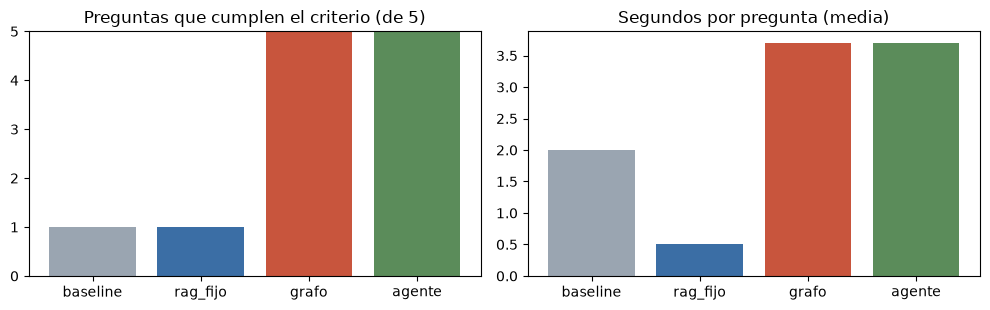

In [10]:
CACHE_PATH = Path("evaluacion_cache.json")
RUNNERS = {
    "baseline": lambda item: ask_baseline(item["pregunta"]),
    "rag_fijo": lambda item: ask_rag(item["pregunta"]),
    "grafo": lambda item: ask_graph(graph_stateless, item["pregunta"], f"eval-{item['id']}"),
    "agente": lambda item: ask_agent(item["pregunta"], f"eval-{item['id']}"),
}
results = json.loads(CACHE_PATH.read_text()) if CACHE_PATH.exists() else {}
missing = [(item, name) for item in QUESTIONS for name in RUNNERS if name not in results.get(item["id"], {})]
for item, name in missing:
    results.setdefault(item["id"], {})[name] = RUNNERS[name](item)
if missing:
    CACHE_PATH.write_text(json.dumps(results, ensure_ascii=False, indent=1))
print("Respuestas generadas en esta ejecución:", len(missing))

ORDER = list(RUNNERS)


def page_mentions(source, page, word):
    found = vectorstore.get(where={"$and": [{"source": source}, {"page": int(page)}]}, include=["documents"])
    return any(word in text.lower() for text in found["documents"])


def evaluate(question_id, record):
    citations = CITATION.findall(record["answer"])
    supported = [(s, p) for s, p in citations if f"({s}, p. {p})" in record["evidence"]]
    if question_id == "P3":
        passes = re.search(rf"\b{COUNT_2024}\b", record["answer"]) is not None
    elif question_id == "P5":
        passes = record["answer"].strip() == "SIN_EVIDENCIA"
    elif question_id == "P4":
        passes = any(source.startswith("2023") and page_mentions(source, page, "diffusion") for source, page in supported)
    else:
        passes = len(supported) >= 1
    return {
        "citas": len(citations),
        "citas válidas": sum(citation_exists(s, p) for s, p in citations),
        "citas respaldadas": len(supported),
        "cumple": passes,
        "segundos": record["seconds"],
    }


evaluation = pd.DataFrame(
    [{"pregunta": qid, "configuración": name, **evaluate(qid, record)} for qid, by_config in results.items() for name, record in by_config.items()]
)
display(evaluation.pivot(index="pregunta", columns="configuración", values="cumple")[ORDER])
summary = (
    evaluation.groupby("configuración")
    .agg(cumplidas=("cumple", "sum"), citas=("citas", "sum"), validas=("citas válidas", "sum"), respaldadas=("citas respaldadas", "sum"), segundos_medios=("segundos", "mean"))
    .loc[ORDER]
    .round(1)
)
display(summary)

pd.set_option("display.max_colwidth", 150)
display(
    pd.DataFrame(
        {
            "consultas del grafo (nodo reescribir)": [" | ".join(results[q["id"]]["grafo"]["plan"]["variants"]) for q in QUESTIONS],
            "llamadas del agente": ["; ".join(results[q["id"]]["agente"]["tool_calls"]) or "ninguna" for q in QUESTIONS],
        },
        index=[q["id"] for q in QUESTIONS],
    )
)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
colors = ["#9aa5b1", "#3b6ea5", "#c8553d", "#5b8c5a"]
axes[0].bar(ORDER, summary["cumplidas"], color=colors)
axes[0].set_ylim(0, 5)
axes[0].set_title("Preguntas que cumplen el criterio (de 5)")
axes[1].bar(ORDER, summary["segundos_medios"], color=colors)
axes[1].set_title("Segundos por pregunta (media)")
plt.tight_layout()
plt.show()

## 9. Interpretación de resultados y conclusiones

**Interpretación.** El LLM solo inventa: describe métodos sin fuente y cita archivos genéricos que no existen, por eso ninguna de sus citas es válida. El RAG fijo recupera fragmentos irrelevantes porque la pregunta está en español y el índice en inglés: en P1 y P2 se abstuvo, pero en P4 respondió con un artículo de 2025 presentado como de 2023, una cita respaldada por lo recuperado que no responde la pregunta. El grafo cumple los cinco criterios; en las preguntas de búsqueda todas sus citas existen y están respaldadas, mientras que P3 y P5 se cumplen sin citas, por el conteo y por la abstención. El agente también cumple los cinco con el mismo tiempo medio, con consultas más cortas y sin nodo de reescritura; en P5 se abstuvo sin llamar ninguna herramienta, por decisión propia y no por el umbral. La diferencia entre ambos no está en el puntaje sino en el control: el pipeline garantiza que siempre se reescriba con el historial, se filtre y se aplique el umbral, mientras que en el agente esos pasos dependen de lo que decida en cada turno, como se vio en el segundo turno de la sección 7. En estas cinco preguntas cada fallo de las referencias coincide con algo que hace un nodo (la traducción, el conteo, el filtro por año, el umbral), pero con este tamaño de muestra es una lectura de los casos, no una relación causal medida. El costo de ambos es tiempo: varias llamadas al LLM por pregunta en lugar de una.

**Conclusiones.**

1. La recuperación densa depende del idioma: la similitud de las consultas en español se solapa con la de las consultas fuera de tema, y reescribir al inglés fue la mejora más grande del sistema.
2. Un umbral de similitud coseno permite abstenerse sin gastar una llamada al modelo.
3. Las herramientas dan resultados exactos donde el LLM no puede, como contar artículos por año.
4. En el pipeline la memoria actúa sobre la reescritura de la consulta, que es donde se resuelven las referencias entre turnos; en el agente el historial está disponible y lo usó solo en parte al construir la búsqueda.
5. Validar las citas fuera del modelo fue necesario: sin recuperación el modelo produjo citas con apariencia válida que no existen.
6. Pipeline y agente empatan en estas cinco preguntas. El pipeline da control y trazabilidad de cada paso; el agente da flexibilidad a cambio de no garantizar pasos como la reescritura con historial. Para una base de conocimiento en otro idioma, ese paso garantizado es el que más pesa.

**Limitaciones.** Son cinco preguntas con una sola ejecución a temperatura 0, así que no hay estadística. El diseño se ajustó después de una primera ejecución con esas mismas preguntas (el año por expresión regular, el prompt de conteo y el delimitador de las citas), de modo que el resultado perfecto del pipeline puede estar sobreajustado a ellas; el agente se evaluó una sola vez y sin ajustes. Una cita respaldada prueba que el fragmento se recuperó, no que la afirmación sea correcta, y no se revisó cada respuesta a mano; además, el modelo copia a veces referencias numéricas de los papers, como `[36]`. La expresión regular toma cualquier año de la pregunta, incluido el 2025 de P5, así que esa búsqueda se filtró por un año que la pregunta no pedía como filtro; la abstención sale igualmente del umbral, pero el filtro no era pertinente. El umbral se calibró con doce consultas y los rangos del español y de lo ajeno al tema se solapan. La memoria no restringe la respuesta a los artículos del primer turno. Una parte del corpus no se indexó porque los archivos de origen no eran PDFs o no se pudieron leer. Y el modelo de 4B parámetros y los embeddings, entrenados sobre todo en inglés, limitan lo que el sistema puede hacer.